# Inter-individual variation in the CRC gut microbiome

Combined analysis notebook for NCBI BioProject PRJNA743150 (Choi et al.).

**Pipeline order**

| Section | Contents |
|---|---|
| 1 | Import QIIME 2 outputs |
| 2 | Clean, collapse to genus, filter |
| 3 | CLR transform |
| 4 | Metadata and derived labels |
| 5 | Ordination of all samples (PCA, t-SNE) |
| 6 | Cosine-similarity permutation test |
| 7 | Within-patient difference matrix |
| 8 | Tumor vs. normal: unpaired RFC |
| 9 | Tumor vs. normal: paired RFC |
| 10 | Ordination of the +/- difference matrix |
| 11 | Feature importance, Wilcoxon, **Benjamini-Hochberg** |
| 12 | Recurrence classifiers (negative result) |
| A, B | Appendices: Shannon diversity, superseded single-split models |

**Conventions used throughout**

- `clrGenera` is genera x samples; `clrTable` is samples x genera. The transpose
  happens once, in section 3, so re-running a cell can never flip the orientation.
- `delta_df` (patients x genera, tumor minus normal on the CLR scale) is built once
  in section 7 and reused by sections 9, 11 and 12.
- Every cross-validation split that involves individual biopsies is grouped by
  patient, so a patient's two samples never straddle the train/test boundary.

## 0. Setup

In [1]:
import io
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import (
    StratifiedGroupKFold, GroupKFold, StratifiedKFold, RepeatedStratifiedKFold,
    cross_val_predict, cross_val_score, cross_validate, permutation_test_score,
    train_test_split,
)
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay,
)

from scipy.stats import wilcoxon, entropy

pd.set_option("display.width", 120)

### Configuration

Point `DATA_DIR` at the folder holding the three QIIME 2 exports. Everything else
is derived from it, so this is the only path that needs editing on another machine.

In [ ]:
DATA_DIR = Path(r"C:\Users\barth\Downloads")  

FREQ_TABLE = DATA_DIR / "table.tsv"
TAXONOMY   = DATA_DIR / "taxonomy.tsv"
METADATA   = DATA_DIR / "crc_metadata.tsv"

for p in (FREQ_TABLE, TAXONOMY, METADATA):
    print(f"{'OK ' if p.exists() else 'MISSING'}  {p}")

#filtering thresholds
MIN_PREVALENCE = 3      # genus must appear in at least this many samples
MIN_TOTAL_COUNT = 20    # have at least this many reads in total

# resampling sizes
N_PERM_COSINE = 10_000  # cosine-similarity permutation test
N_PERM_RFC    = 200     # tumor vs. normal classifier permutation tests
N_PERM_REC    = 1_000   # recurrence classifier permutation tests
N_REPEATS     = 20      # repeats of 5-fold CV for the recurrence models
RANDOM_STATE  = 42

# figure export 
SAVE_FIGS = True
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
FIG_DPI = 300           # PLOS ONE requires 300-600 dpi
FIG_FORMAT = "tiff"     # PLOS ONE accepts TIFF or EPS; use "png" for quick looks

# PLOS ONE width limits, in pixels at FIG_DPI (2.63 in to 7.5 in).
PLOS_MIN_PX, PLOS_MAX_PX = 789, 2250

# PLOS allows Arial, Times or Symbol at 8-12 pt inside figures.
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
plt.rcParams["font.size"] = 10


def save_fig(name, fig=None):
    """Save the current figure at publication resolution, inside PLOS width limits.

    `bbox_inches="tight"` makes the final pixel width hard to predict, so the
    figure is rendered to a buffer, measured, and rescaled until it lands in
    range. Rescaling changes the canvas size but not the font point size, so
    text ends up relatively larger on a shrunken figure - check anything dense
    for crowding after the first run.
    """
    if not SAVE_FIGS:
        return
    fig = fig or plt.gcf()
    ext = "tif" if FIG_FORMAT == "tiff" else FIG_FORMAT
    path = FIG_DIR / f"{name}.{ext}"
    kwargs = {"pil_kwargs": {"compression": "tiff_lzw"}} if FIG_FORMAT == "tiff" else {}

    original_size = fig.get_size_inches().copy()
    try:
        for _ in range(4):
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=FIG_DPI, bbox_inches="tight")
            buf.seek(0)
            width_px = Image.open(buf).size[0]
            if width_px > PLOS_MAX_PX:
                scale = (PLOS_MAX_PX / width_px) * 0.995
            elif width_px < PLOS_MIN_PX:
                scale = (PLOS_MIN_PX / width_px) * 1.02
            else:
                break
            fig.set_size_inches(fig.get_size_inches() * scale)
        fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight", **kwargs)
    finally:
        fig.set_size_inches(original_size)   # leave the on-screen figure untouched

    # PLOS wants RGB with no transparency layer; matplotlib writes RGBA.
    im = Image.open(path)
    if im.mode != "RGB":
        flat = Image.new("RGB", im.size, "white")
        flat.paste(im, mask=im.getchannel("A") if "A" in im.getbands() else None)
        flat.save(path, dpi=(FIG_DPI, FIG_DPI),
                  **({"compression": "tiff_lzw"} if FIG_FORMAT == "tiff" else {}))

    w, h = Image.open(path).size
    status = "ok" if PLOS_MIN_PX <= w <= PLOS_MAX_PX else "CHECK WIDTH"
    mode = Image.open(path).mode
    print(f"saved -> {path}  ({w}x{h} px, {w / FIG_DPI:.2f} in wide) [{status}, {mode}]")

In [3]:
def bh_adjust(pvals):
    """Benjamini-Hochberg adjusted p-values (q-values), same order as the input."""
    p = np.asarray(pvals, dtype=float)
    n = p.size
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]   # enforce monotonicity
    q = np.minimum(q, 1.0)
    out = np.empty(n, dtype=float)
    out[order] = q
    return out

## 1. Import data

In [4]:
freqTable = pd.read_csv(FREQ_TABLE, sep="\t", skiprows=1)
freqTable = freqTable.rename(columns={"#OTU ID": "FeatureID"})
print(f"Feature table: {freqTable.shape[0]} ASVs x {freqTable.shape[1] - 1} samples")
freqTable.head()

Feature table: 27600 ASVs x 101 samples


,FeatureID,SRR15018640,SRR15018641,SRR15018642,SRR15018643,SRR15018644,SRR15018645,SRR15018646,SRR15018647,SRR15018648,...,SRR15018731,SRR15018732,SRR15018733,SRR15018734,SRR15018735,SRR15018736,SRR15018737,SRR15018738,SRR15018739,SRR15018740
0,47f27fc06a83dc52f45c8377103c1540,634.0,378.0,1394.0,1282.0,1526.0,1529.0,1237.0,1005.0,698.0,...,1935.0,1056.0,1098.0,2482.0,3241.0,925.0,154.0,288.0,1227.0,2898.0
1,6801b02d1ef62a4cd2ab73f4f39c0bcf,483.0,323.0,1141.0,982.0,1220.0,1123.0,930.0,719.0,490.0,...,1479.0,897.0,970.0,2086.0,2626.0,785.0,95.0,213.0,1063.0,2577.0
2,f204981ee8c56f364d1ff252708c0acc,540.0,354.0,1192.0,1009.0,1152.0,1141.0,890.0,726.0,545.0,...,1510.0,856.0,923.0,2120.0,2570.0,821.0,122.0,194.0,1019.0,2466.0
3,a3cf5ec67c5c5b9d53367f9262e0f05e,516.0,276.0,1130.0,1034.0,1264.0,1251.0,1018.0,779.0,550.0,...,1450.0,888.0,879.0,2026.0,2559.0,819.0,127.0,236.0,970.0,2388.0
4,d4306a4038812836c0f74289076a05ab,358.0,170.0,1029.0,947.0,820.0,717.0,928.0,940.0,527.0,...,1261.0,649.0,607.0,1923.0,3440.0,751.0,0.0,0.0,851.0,2457.0


In [5]:
tax = pd.read_csv(TAXONOMY, sep="\t", skiprows=1, header=None)
tax.columns = ["FeatureID", "Taxon", "Confidence"]
print(f"Taxonomy rows: {len(tax)}")
tax.head()

Taxonomy rows: 27600


,FeatureID,Taxon,Confidence
0,47f27fc06a83dc52f45c8377103c1540,d__Bacteria;p__Proteobacteria;c__Alphaproteoba...,0.718252
1,6801b02d1ef62a4cd2ab73f4f39c0bcf,d__Bacteria,0.717686
2,f204981ee8c56f364d1ff252708c0acc,d__Bacteria;p__Proteobacteria;c__Alphaproteoba...,0.704366
3,a3cf5ec67c5c5b9d53367f9262e0f05e,d__Bacteria;p__Proteobacteria;c__Alphaproteoba...,0.767145
4,d4306a4038812836c0f74289076a05ab,d__Bacteria;p__Proteobacteria;c__Alphaproteoba...,0.831097


## 2. Clean and collapse to genus

ASVs whose taxonomy string matches any term in `UNWANTED` are dropped, the rest are
summed within genus, and genera that are rare or low-abundance are removed.

Note that ASVs without a genus-level call are collected into a single pseudo-genus
named `Unassigned`, which the `UNWANTED` filter then removes.

In [6]:
UNWANTED = ["Unassigned", "Mitochondria", "Eukaryota", "uncultured"]

tax["Genus"] = tax["Taxon"].str.extract(r"g__([^;]+)")
tax["Genus"] = tax["Genus"].fillna("Unassigned")

merged = freqTable.merge(tax[["FeatureID", "Taxon", "Genus"]], on="FeatureID")

mask = merged["Taxon"].str.contains("|".join(UNWANTED), case=False, na=False)
filtered = merged[~mask]
removed = merged[mask]

sample_cols = [c for c in freqTable.columns if c != "FeatureID"]
print(f"ASVs kept:    {len(filtered):>6}   reads: {filtered[sample_cols].sum().sum():>12,}")
print(f"ASVs removed: {len(removed):>6}   reads: {removed[sample_cols].sum().sum():>12,}")

genusTable = filtered.groupby("Genus").sum(numeric_only=True)
print(f"\nGenera before abundance/prevalence filter: {genusTable.shape[0]}")

ASVs kept:      9781   reads:  1,953,693.0
ASVs removed:  17819   reads:  1,701,215.0

Genera before abundance/prevalence filter: 200


In [7]:
totalCounts = genusTable.sum(axis=1)
prevalence = (genusTable > 0).sum(axis=1)

genusTableFiltered = genusTable[(prevalence >= MIN_PREVALENCE) & (totalCounts >= MIN_TOTAL_COUNT)]

print(f"Genera retained: {genusTableFiltered.shape[0]} "
      f"(prevalence >= {MIN_PREVALENCE}, total count >= {MIN_TOTAL_COUNT})")
print(f"Samples:         {genusTableFiltered.shape[1]}")

Genera retained: 134 (prevalence >= 3, total count >= 20)
Samples:         101


## 3. Centered log-ratio transform

16S read counts are compositional, so a CLR transform is applied after adding a
pseudocount of 1. The geometric mean is taken per sample (down the genus axis of the
genera x samples table).

This is the one place the table is transposed. From here on:

- `clrGenera` is **genera x samples**
- `clrTable` is **samples x genera** and is what every later section uses

In [8]:
data = genusTableFiltered + 1                      # pseudocount
geomMean = np.exp(np.log(data).mean(axis=0))       # geometric mean per sample

clrGenera = np.log(data / geomMean)                # genera x samples
clrTable = clrGenera.T.astype(float)               # samples x genera  <-- single transpose

print(f"clrGenera (genera x samples): {clrGenera.shape}")
print(f"clrTable  (samples x genera): {clrTable.shape}")
clrTable.iloc[:3, :5]

clrGenera (genera x samples): (134, 101)
clrTable  (samples x genera): (101, 134)


Genus,Actinomyces,Aeromonas,Agathobacter,Akkermansia,Alistipes
SRR15018640,-1.286807,-1.286807,-1.286807,5.091620,4.386517
SRR15018641,-0.395920,-0.395920,-0.395920,-0.395920,-0.395920
SRR15018642,-0.316812,-0.316812,-0.316812,-0.316812,-0.316812


## 4. Metadata and derived labels

`meta` is aligned to `clrTable.index` and carries every label used downstream:

| Column | Meaning |
|---|---|
| `Sample Name` | e.g. `1042-TT` |
| `patient` | the numeric prefix, e.g. `1042` |
| `tissue_code` | `TT` (tumor) or `TN` (normal) |
| `tissue_type` | `CRC tumor` / `CRC normal` |
| `recurrence` | `recurrent` / `non-recurrent` |
| `AgeGroup` | binned `AGE` |

In [9]:
meta_raw = pd.read_csv(METADATA, sep="\t").set_index("sample-id")

# Keep only samples that survived filtering, in clrTable order.
shared_samples = clrTable.index.intersection(meta_raw.index)
clrTable = clrTable.loc[shared_samples]
meta = meta_raw.loc[shared_samples].copy()

meta["AgeGroup"] = pd.cut(meta["AGE"], bins=[0, 40, 60, 80, 100],
                          labels=["<40", "40-60", "60-80", "80+"])

meta["recurrence"] = meta["tissue"].apply(
    lambda x: "recurrent" if "recurrent CRC" in x and "non-recurrent" not in x
    else "non-recurrent"
)
meta["tissue_type"] = meta["tissue"].apply(
    lambda x: "CRC tumor" if "tumor" in x else "CRC normal"
)
meta["patient"] = meta["Sample Name"].astype(str).str.split("-").str[0]
meta["tissue_code"] = meta["Sample Name"].astype(str).str.split("-").str[-1]

assert clrTable.index.equals(meta.index), "clrTable and meta are out of alignment"

print(f"Samples:  {len(meta)}")
print(f"Patients: {meta['patient'].nunique()}")
print()
print(meta["tissue_type"].value_counts().to_string())
print()
print(meta["recurrence"].value_counts().to_string())
meta[["Sample Name", "patient", "tissue_code", "tissue_type", "recurrence"]].head()

Samples:  101
Patients: 51

tissue_type
CRC normal    51
CRC tumor     50

recurrence
non-recurrent    66
recurrent        35


,Sample Name,patient,tissue_code,tissue_type,recurrence
SRR15018640,12002841-TN,12002841,TN,CRC normal,recurrent
SRR15018641,12002841-TT,12002841,TT,CRC tumor,recurrent
SRR15018642,12002385-TN,12002385,TN,CRC normal,recurrent
SRR15018643,12002385-TT,12002385,TT,CRC tumor,recurrent
SRR15018644,12001512-TN,12001512,TN,CRC normal,recurrent


In [10]:
# Patients contributing both a tumor and a normal biopsy.
pair_counts = meta.groupby("patient")["tissue_code"].nunique()
paired_patients = sorted(pair_counts[pair_counts == 2].index)

print(f"Patients with a complete tumor/normal pair: {len(paired_patients)}")
print(f"Patients missing one tissue:                {(pair_counts != 2).sum()}")

# Recurrence status of the paired patients (one row per patient).
patient_recurrence = (meta.drop_duplicates("patient")
                          .set_index("patient")["recurrence"]
                          .loc[paired_patients])
print()
print(patient_recurrence.value_counts().to_string())

Patients with a complete tumor/normal pair: 50
Patients missing one tissue:                1

recurrence
non-recurrent    33
recurrent        17


## 5. Ordination of all samples

PCA and t-SNE on the full sample set.

In [11]:
X_all = clrTable.values

pca_all = PCA(n_components=min(10, X_all.shape[1]))
coords_pca = pca_all.fit_transform(X_all)
explained = pca_all.explained_variance_ratio_ * 100

print(f"Variance explained - PC1: {explained[0]:.1f}%  PC2: {explained[1]:.1f}%")

Variance explained - PC1: 11.7%  PC2: 8.4%


saved -> figures\pca_recurrence.tif  (2245x1693 px, 7.48 in wide) [ok]


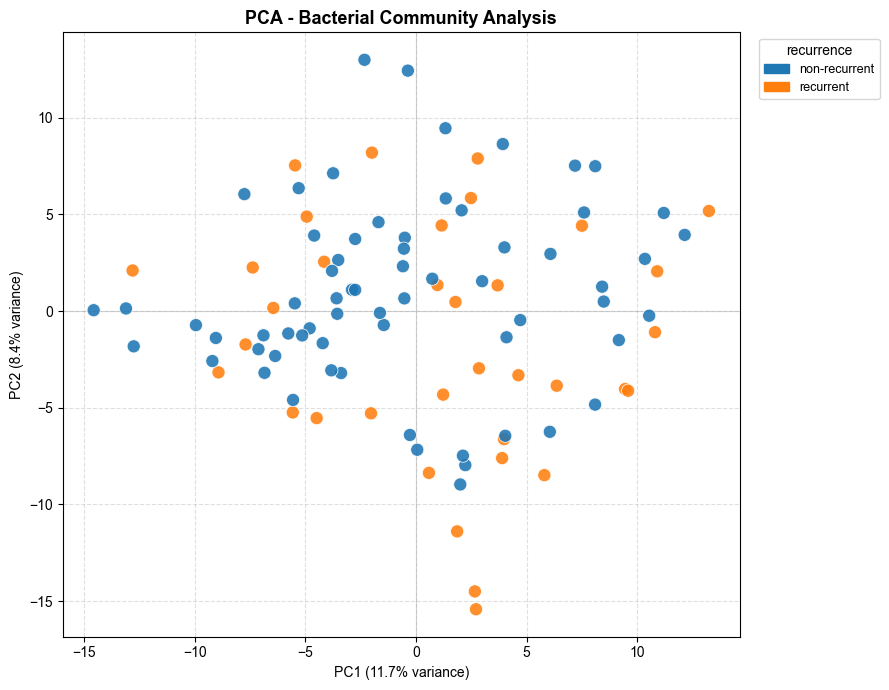

In [12]:
def scatter_by_group(coords, labels, title, xlab, ylab, legend_title,
                     figsize=(9, 7), palette=None, show_legend=True, grid=True):
    """Scatter `coords` coloured by `labels`, returning the axis."""
    labels = pd.Series(labels).astype(str).values
    groups = sorted(pd.unique(labels))
    palette = palette or plt.cm.tab10.colors
    cmap = {g: palette[i % len(palette)] for i, g in enumerate(groups)}

    fig, ax = plt.subplots(figsize=figsize)
    ax.scatter(coords[:, 0], coords[:, 1], c=[cmap[g] for g in labels],
               s=90, edgecolors="white", linewidths=0.6, alpha=0.88, zorder=3)
    if show_legend:
        ax.legend(handles=[mpatches.Patch(color=cmap[g], label=g) for g in groups],
                  title=legend_title, bbox_to_anchor=(1.02, 1), loc="upper left",
                  frameon=True, fontsize=9)
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.set_title(title, fontsize=13, fontweight="bold")
    if grid:
        ax.grid(True, linestyle="--", alpha=0.4, zorder=0)
    return fig, ax


fig, ax = scatter_by_group(
    coords_pca, meta["recurrence"],
    title="PCA - Bacterial Community Analysis",
    xlab=f"PC1 ({explained[0]:.1f}% variance)",
    ylab=f"PC2 ({explained[1]:.1f}% variance)",
    legend_title="recurrence",
)
ax.axhline(0, color="lightgray", lw=0.8, zorder=1)
ax.axvline(0, color="lightgray", lw=0.8, zorder=1)
plt.tight_layout()
save_fig("pca_recurrence")
plt.show()

In [13]:
tsne_all = TSNE(n_components=2, perplexity=30, max_iter=1000,
                learning_rate="auto", init="pca", random_state=RANDOM_STATE)
coords_tsne = tsne_all.fit_transform(X_all)
print(f"t-SNE KL divergence: {tsne_all.kl_divergence_:.4f}")

t-SNE KL divergence: 0.3877


saved -> figures\tsne_recurrence.tif  (2243x1549 px, 7.48 in wide) [ok]


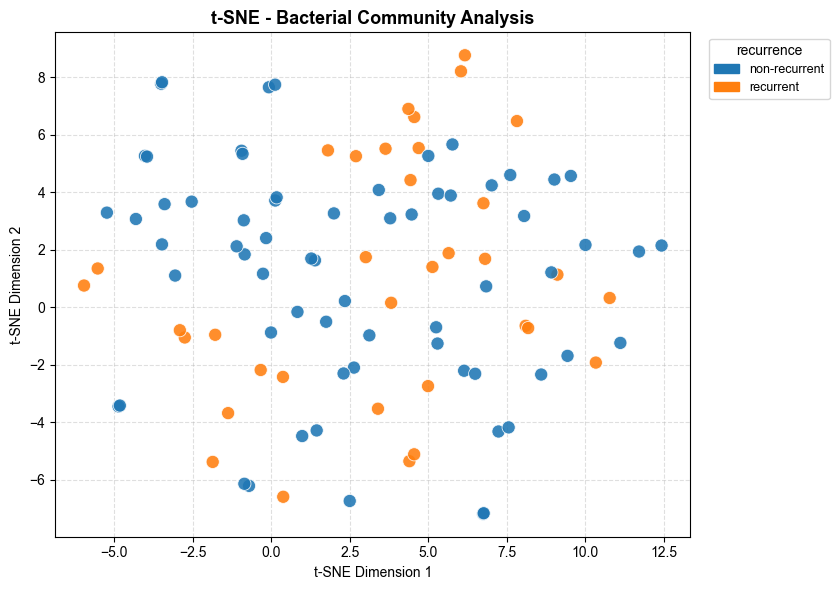

In [14]:
scatter_by_group(
    coords_tsne, meta["recurrence"],
    title="t-SNE - Bacterial Community Analysis",
    xlab="t-SNE Dimension 1", ylab="t-SNE Dimension 2",
    legend_title="recurrence", figsize=(8.5, 6),
)
plt.tight_layout()
save_fig("tsne_recurrence")
plt.show()

saved -> figures\tsne_pairs.tif  (2241x1748 px, 7.47 in wide) [ok]


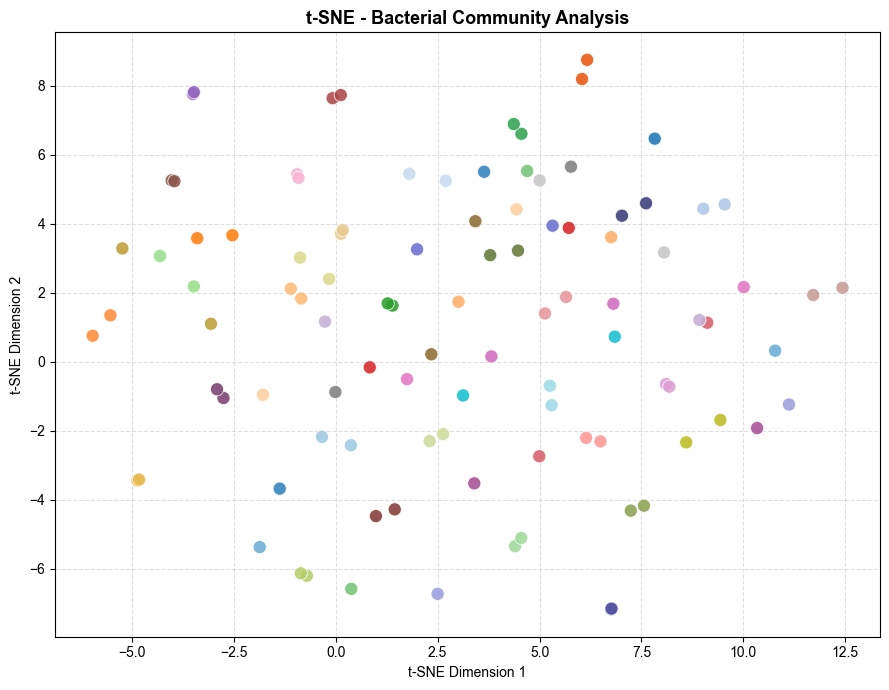

In [15]:
# Same embedding, coloured by patient: this is the pairing result.
patient_palette = (plt.cm.tab20.colors + plt.cm.tab20b.colors + plt.cm.tab20c.colors)

scatter_by_group(
    coords_tsne, meta["patient"],
    title="t-SNE - Bacterial Community Analysis",
    xlab="t-SNE Dimension 1", ylab="t-SNE Dimension 2",
    legend_title="Patient", figsize=(9, 7),
    palette=patient_palette, show_legend=False,
)
plt.tight_layout()
save_fig("tsne_pairs")
plt.show()

## 6. Cosine-similarity permutation test

Each patient's normal and tumor profiles are L2-normalised and their dot product
taken. The test statistic is the mean of those similarities across patients.

Under the null, tumor profiles are reassigned to patients at random. The loop is
vectorised, which computes the identical statistic as the original element-wise
version but runs in seconds rather than minutes.

In [16]:
norm_df = (clrTable[meta["tissue_code"] == "TN"]
           .set_index(meta.loc[meta["tissue_code"] == "TN", "patient"]))
crc_df  = (clrTable[meta["tissue_code"] == "TT"]
           .set_index(meta.loc[meta["tissue_code"] == "TT", "patient"]))

shared = norm_df.index.intersection(crc_df.index).sort_values()
norm_df = norm_df.loc[shared].astype(float)
crc_df  = crc_df.loc[shared].astype(float)

print(f"Paired patients: {len(shared)}")
print(f"norm_df shape:   {norm_df.shape}")
print(f"crc_df shape:    {crc_df.shape}")

Paired patients: 50
norm_df shape:   (50, 134)
crc_df shape:    (50, 134)


In [17]:
def l2_rows(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

N = l2_rows(norm_df.values)
C = l2_rows(crc_df.values)

observed_cos = float(np.sum(N * C, axis=1).mean())
print(f"Number of pairs:  {len(N)}")
print(f"Mean similarity:  {observed_cos:.4f}")

Number of pairs:  50
Mean similarity:  0.7201


In [18]:
rng = np.random.default_rng(RANDOM_STATE)
null_cos = np.array([
    np.sum(N[rng.permutation(len(N))] * C, axis=1).mean()
    for _ in range(N_PERM_COSINE)
])

n_ge = int(np.sum(null_cos >= observed_cos))
p_cos = (n_ge + 1) / (N_PERM_COSINE + 1)   # add-one convention, never reports p = 0

print(f"Null mean:        {null_cos.mean():.4f}")
print(f"Null max:         {null_cos.max():.4f}")
print(f"Shuffles >= observed: {n_ge} / {N_PERM_COSINE}")
print(f"p = {p_cos:.5f}" + ("  (p < 0.0001)" if p_cos < 1e-4 else ""))

Null mean:        0.4625
Null max:         0.5188
Shuffles >= observed: 0 / 10000
p = 0.00010  (p < 0.0001)


saved -> figures\cosine_permutation.tif  (2241x1389 px, 7.47 in wide) [ok]


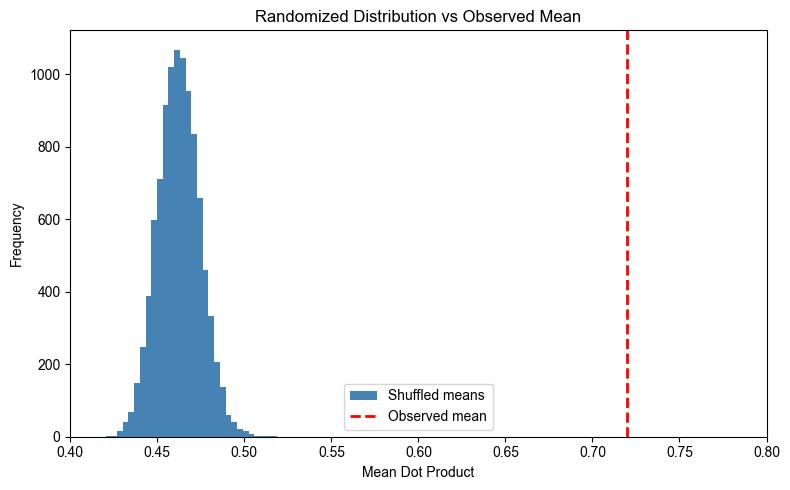

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(null_cos, bins=30, color="steelblue", label="Shuffled means")
plt.axvline(observed_cos, color="red", linestyle="--", linewidth=2, label="Observed mean")
plt.xlabel("Mean Dot Product")
plt.ylabel("Frequency")
plt.xlim(0.4, 0.8)
plt.legend()
plt.title("Randomized Distribution vs Observed Mean")
plt.tight_layout()
save_fig("cosine_permutation")
plt.show()

## 7. Within-patient difference matrix

`delta_df` holds one row per paired patient:

$$d_i = x_i^{\text{tumor}} - x_i^{\text{normal}}$$

on the CLR scale. Built once here; sections 9, 11 and 12 all reuse it.

In [20]:
tumor_p  = crc_df.loc[paired_patients]
normal_p = norm_df.loc[paired_patients]

delta_df = (tumor_p - normal_p).astype(float)
delta_df.index.name = "patient"

assert delta_df.isna().sum().sum() == 0, "NaNs in delta_df - check patient alignment"
print(f"delta_df (patients x genera): {delta_df.shape}")
delta_df.iloc[:3, :5]

delta_df (patients x genera): (50, 134)


Genus,Actinomyces,Aeromonas,Agathobacter,Akkermansia,Alistipes
patient,,,,,
11000047,-0.220953,2.418104,-0.220953,-0.220953,-0.220953
11000095,0.435968,0.435968,-3.994849,-0.094661,-1.551907
11000142,-0.549832,0.094526,0.094526,0.094526,0.094526


## 8. Tumor vs. normal - unpaired classifier

Each biopsy is an independent row. Folds are grouped by patient so a model is never
tested on a patient it trained on; without that constraint the inter-individual
signal from section 6 would inflate the score.

In [21]:
X_tt = clrTable.values
y_tt = (meta["tissue_type"] == "CRC tumor").astype(int).values   # 1 = tumor
groups_tt = meta["patient"].values

rf_tt = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", min_samples_leaf=2,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
)
cv_tt = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

proba_tt = cross_val_predict(rf_tt, X_tt, y_tt, groups=groups_tt,
                             cv=cv_tt, method="predict_proba")[:, 1]
pred_tt = (proba_tt >= 0.5).astype(int)

print(classification_report(y_tt, pred_tt, target_names=["normal", "tumor"]))
print(f"Pooled ROC AUC: {roc_auc_score(y_tt, proba_tt):.3f}")

              precision    recall  f1-score   support

      normal       0.68      0.75      0.71        51
       tumor       0.71      0.64      0.67        50

    accuracy                           0.69       101
   macro avg       0.69      0.69      0.69       101
weighted avg       0.69      0.69      0.69       101

Pooled ROC AUC: 0.750


saved -> figures\unpaired_tn_roc_confusion.tif  (2244x1027 px, 7.48 in wide) [ok]


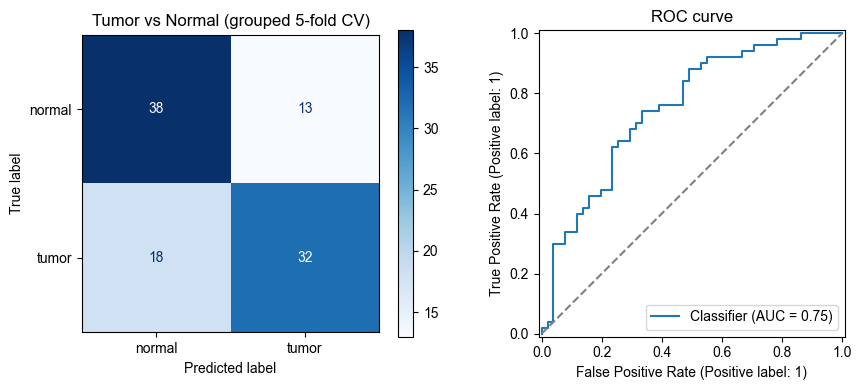

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay.from_predictions(
    y_tt, pred_tt, display_labels=["normal", "tumor"], cmap="Blues", ax=axes[0])
axes[0].set_title("Tumor vs Normal (grouped 5-fold CV)")
RocCurveDisplay.from_predictions(y_tt, proba_tt, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("ROC curve")
plt.tight_layout()
save_fig("unpaired_tn_roc_confusion")
plt.show()

Observed AUC: 0.765 | Null mean: 0.500 | p = 0.0050
(smallest attainable p with 200 permutations: 0.0050)
saved -> figures\perm_unpaired_tn.tif  (2240x1390 px, 7.47 in wide) [ok]


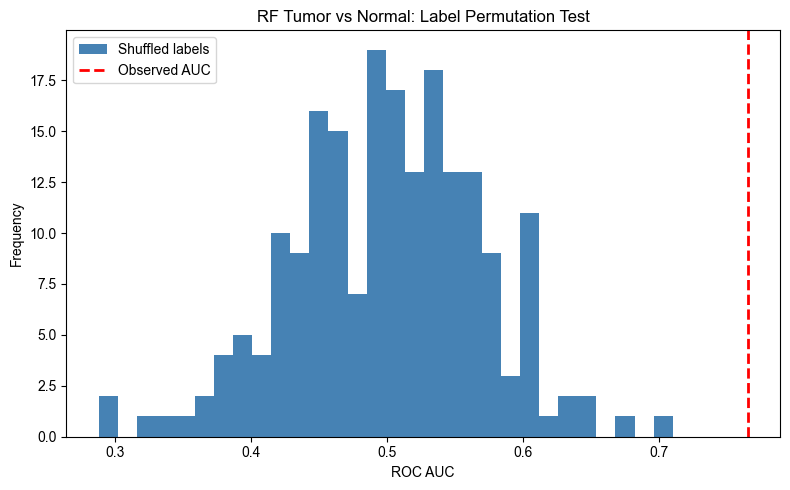

In [23]:
# Labels are swapped within each patient: equivalent to randomly choosing which of
# a patient's two biopsies gets called the tumor.
score_tt, perm_tt, p_tt = permutation_test_score(
    rf_tt, X_tt, y_tt, groups=groups_tt, cv=cv_tt,
    scoring="roc_auc", n_permutations=N_PERM_RFC, random_state=RANDOM_STATE,
)
print(f"Observed AUC: {score_tt:.3f} | Null mean: {perm_tt.mean():.3f} | p = {p_tt:.4f}")
print(f"(smallest attainable p with {N_PERM_RFC} permutations: {1 / (N_PERM_RFC + 1):.4f})")

plt.figure(figsize=(8, 5))
plt.hist(perm_tt, bins=30, color="steelblue", label="Shuffled labels")
plt.axvline(score_tt, color="red", linestyle="--", linewidth=2, label="Observed AUC")
plt.xlabel("ROC AUC")
plt.ylabel("Frequency")
plt.legend()
plt.title("RF Tumor vs Normal: Label Permutation Test")
plt.tight_layout()
save_fig("perm_unpaired_tn")
plt.show()

## 9. Tumor vs. normal - paired classifier

Each patient contributes two rows: $+d_i$ labelled as the tumor-minus-normal
direction, and $-d_i$ labelled as the reverse. The model has to learn *which
direction of change* corresponds to tumor, so chance is exactly 50%.

Both rows from a patient stay in the same fold, otherwise a model would be tested
on the mirror image of a row it trained on.

In [24]:
X_pair = np.vstack([delta_df.values, -delta_df.values])
y_pair = np.r_[np.ones(len(delta_df), int), np.zeros(len(delta_df), int)]
groups_pair = np.r_[delta_df.index.values, delta_df.index.values]
n_p = len(delta_df)

print(f"Paired patients: {n_p} | Rows for model: {len(X_pair)}")

rf_pair = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", min_samples_leaf=2,
    random_state=RANDOM_STATE, n_jobs=-1,
)
cv_pair = GroupKFold(n_splits=5)

proba_pair = cross_val_predict(rf_pair, X_pair, y_pair, groups=groups_pair,
                               cv=cv_pair, method="predict_proba")[:, 1]

# Pair-level call: did the true +d row score higher than its -d twin?
pair_correct = proba_pair[:n_p] > proba_pair[n_p:]

print(f"Row-level ROC AUC:   {roc_auc_score(y_pair, proba_pair):.3f}")
print(f"Pair-level accuracy: {pair_correct.mean():.3f} "
      f"({pair_correct.sum()}/{n_p} patients, chance = 0.5)")

Paired patients: 50 | Rows for model: 100
Row-level ROC AUC:   0.913
Pair-level accuracy: 0.820 (41/50 patients, chance = 0.5)


saved -> figures\paired_tn_roc.tif  (1438x1463 px, 4.79 in wide) [ok]


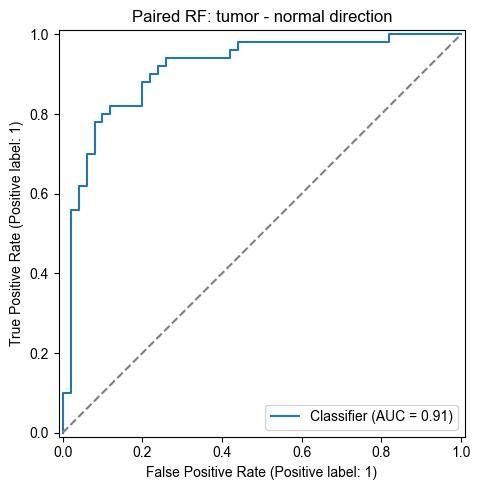

In [25]:
fig, ax = plt.subplots(figsize=(5.5, 5))
RocCurveDisplay.from_predictions(y_pair, proba_pair, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Paired RF: tumor - normal direction")
plt.tight_layout()
save_fig("paired_tn_roc")
plt.show()

Observed AUC: 0.904 | Null mean: 0.501 | p = 0.0050
saved -> figures\perm_paired_tn.tif  (2249x1396 px, 7.50 in wide) [ok]


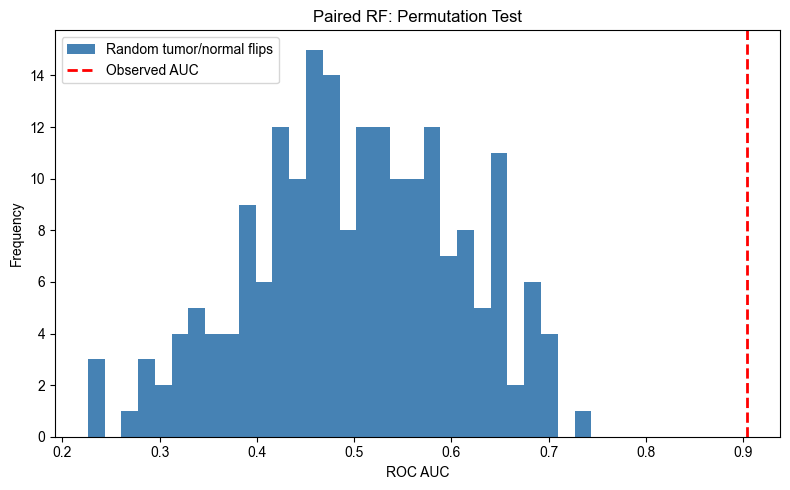

In [26]:
score_pair, perm_pair, p_pair = permutation_test_score(
    rf_pair, X_pair, y_pair, groups=groups_pair, cv=cv_pair,
    scoring="roc_auc", n_permutations=N_PERM_RFC, random_state=RANDOM_STATE,
)
print(f"Observed AUC: {score_pair:.3f} | Null mean: {perm_pair.mean():.3f} | p = {p_pair:.4f}")

plt.figure(figsize=(8, 5))
plt.hist(perm_pair, bins=30, color="steelblue", label="Random tumor/normal flips")
plt.axvline(score_pair, color="red", linestyle="--", linewidth=2, label="Observed AUC")
plt.xlabel("ROC AUC")
plt.ylabel("Frequency")
plt.legend()
plt.title("Paired RF: Permutation Test")
plt.tight_layout()
save_fig("perm_paired_tn")
plt.show()

## 10. Ordination of the +/- difference matrix

The matrix is symmetric about the origin by construction, so the overall centroid is
exactly zero while the two class centroids are $\bar{d}$ and $-\bar{d}$. Separation
along PC1 therefore reflects a *shared direction* of tumor-associated change across
patients, not a difference in location.

PC1: 21.3%  PC2: 6.9%  (compare PC1 of the pooled samples: 11.7%)
saved -> figures\pca_delta.tif  (2216x2063 px, 7.39 in wide) [ok]


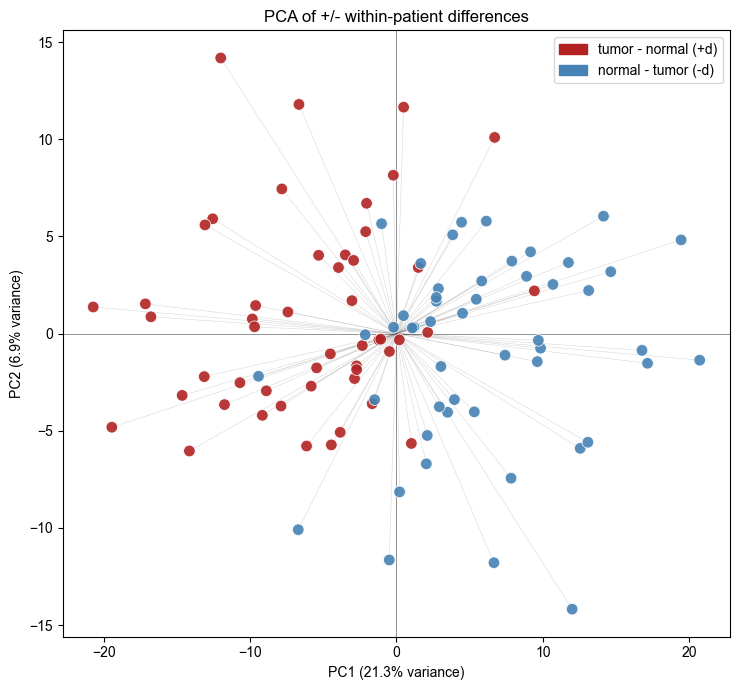

In [27]:
pca_pair = PCA(n_components=10)
coords_pair = pca_pair.fit_transform(X_pair)
exp_pair = pca_pair.explained_variance_ratio_ * 100
print(f"PC1: {exp_pair[0]:.1f}%  PC2: {exp_pair[1]:.1f}%  "
      f"(compare PC1 of the pooled samples: {explained[0]:.1f}%)")

label_colors = np.where(y_pair == 1, "firebrick", "steelblue")
DELTA_LEGEND = [mpatches.Patch(color="firebrick", label="tumor - normal (+d)"),
                mpatches.Patch(color="steelblue", label="normal - tumor (-d)")]


def plot_delta_embedding(coords, title, xlab, ylab, axes_at_zero=False):
    fig, ax = plt.subplots(figsize=(7.5, 7))
    for i in range(n_p):                       # join each patient's mirrored twins
        ax.plot([coords[i, 0], coords[i + n_p, 0]],
                [coords[i, 1], coords[i + n_p, 1]],
                color="gray", lw=0.4, alpha=0.3, zorder=1)
    ax.scatter(coords[:, 0], coords[:, 1], c=label_colors,
               s=70, edgecolors="white", linewidths=0.6, alpha=0.9, zorder=3)
    if axes_at_zero:
        ax.axhline(0, color="black", lw=0.6, alpha=0.5)
        ax.axvline(0, color="black", lw=0.6, alpha=0.5)
    ax.set_xlabel(xlab)
    ax.set_ylabel(ylab)
    ax.set_title(title)
    ax.legend(handles=DELTA_LEGEND)
    plt.tight_layout()
    return fig, ax


plot_delta_embedding(
    coords_pair, "PCA of +/- within-patient differences",
    f"PC1 ({exp_pair[0]:.1f}% variance)", f"PC2 ({exp_pair[1]:.1f}% variance)",
    axes_at_zero=True,
)
save_fig("pca_delta")
plt.show()

t-SNE KL divergence: 0.4750
saved -> figures\tsne_delta.tif  (2215x2062 px, 7.38 in wide) [ok]


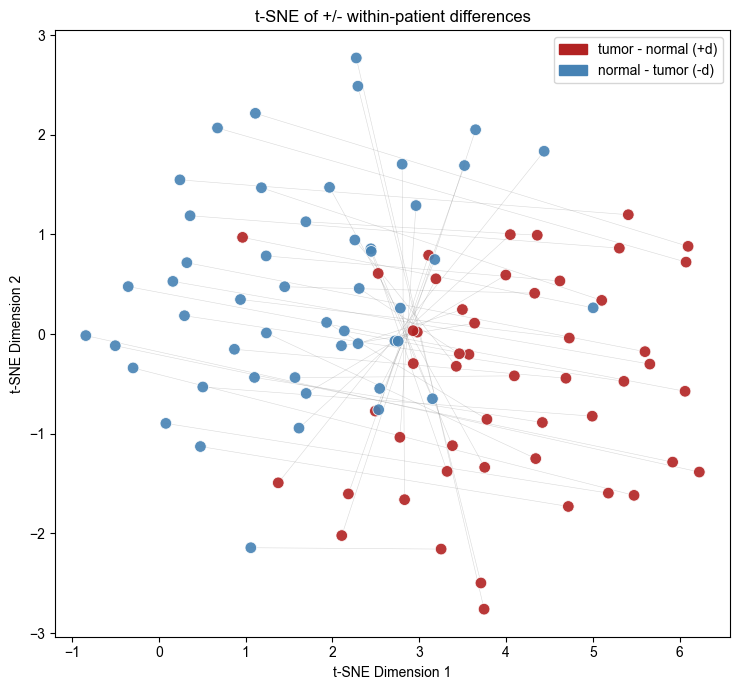

In [28]:
tsne_pair = TSNE(n_components=2, perplexity=30, max_iter=1000,
                 learning_rate="auto", init="pca", random_state=RANDOM_STATE)
coords_tsne_pair = tsne_pair.fit_transform(X_pair)
print(f"t-SNE KL divergence: {tsne_pair.kl_divergence_:.4f}")

plot_delta_embedding(
    coords_tsne_pair, "t-SNE of +/- within-patient differences",
    "t-SNE Dimension 1", "t-SNE Dimension 2",
)
save_fig("tsne_delta")
plt.show()

### Manuscript Fig 5 (print size)

PCA and t-SNE of the +/- difference matrix side by side, drawn at the final
printed width (7.3 in) so the text stays inside PLOS's 8-12 pt range. Upload
`figures/Fig5.tif` as Fig 5. Only needs sections 0-7, so it can be run without
the permutation tests.

In [ ]:
# --- Manuscript Fig 5: PCA and t-SNE of the +/- difference matrix, drawn at print size
# Self-contained: needs only delta_df (section 7) plus the setup cell, so you can run
# sections 0-7 and then this cell without waiting for the permutation tests.
# PCA is deterministic and t-SNE uses the same seed and settings as section 10,
# so the coordinates are identical to the separate plots.

X_f5 = np.vstack([delta_df.values, -delta_df.values])
y_f5 = np.r_[np.ones(len(delta_df), int), np.zeros(len(delta_df), int)]
n_f5 = len(delta_df)

pca_f5 = PCA(n_components=10)
xy_pca = pca_f5.fit_transform(X_f5)
var_f5 = pca_f5.explained_variance_ratio_ * 100
xy_tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, learning_rate="auto",
               init="pca", random_state=RANDOM_STATE).fit_transform(X_f5)

PRINT_STYLE = {"font.size": 9, "axes.labelsize": 9, "axes.titlesize": 10,
               "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8}

with plt.rc_context(PRINT_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.3, 3.7))
    colors_f5 = np.where(y_f5 == 1, "firebrick", "steelblue")
    panels = [
        (axes[0], xy_pca, "PCA",
         f"PC1 ({var_f5[0]:.1f}% variance)", f"PC2 ({var_f5[1]:.1f}% variance)", True),
        (axes[1], xy_tsne, "t-SNE", "t-SNE dimension 1", "t-SNE dimension 2", False),
    ]
    for (ax, xy, title, xlab, ylab, zero_lines), letter in zip(panels, "AB"):
        for i in range(n_f5):                                  # join mirrored twins
            ax.plot([xy[i, 0], xy[i + n_f5, 0]], [xy[i, 1], xy[i + n_f5, 1]],
                    color="gray", lw=0.3, alpha=0.3, zorder=1)
        ax.scatter(xy[:, 0], xy[:, 1], c=colors_f5, s=18,
                   edgecolors="white", linewidths=0.3, alpha=0.9, zorder=3)
        if zero_lines:
            ax.axhline(0, color="black", lw=0.5, alpha=0.5)
            ax.axvline(0, color="black", lw=0.5, alpha=0.5)
        ax.set_xlabel(xlab)
        ax.set_ylabel(ylab)
        ax.set_title(title)
        ax.text(-0.17, 1.04, letter, transform=ax.transAxes,
                fontsize=12, fontweight="bold", va="bottom")
    fig.legend(handles=[mpatches.Patch(color="firebrick", label="tumor - normal (+d)"),
                        mpatches.Patch(color="steelblue", label="normal - tumor (-d)")],
               loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    save_fig("Fig5")
    plt.show()


## 11. Feature importance, Wilcoxon tests and Benjamini-Hochberg correction

1. Impurity importance from `rf_pair` refit on all rows
2. A Wilcoxon signed-rank test per genus on the within-patient differences testing
   whether the shift is centred at zero. This gives the direction and significance.
3. **Benjamini-Hochberg FDR correction.**


In [29]:
rf_pair.fit(X_pair, y_pair)
imp_pair = pd.Series(rf_pair.feature_importances_, index=delta_df.columns)


def wilcoxon_p(series):
    """Signed-rank p-value, returning 1.0 for an all-zero (degenerate) column."""
    v = np.asarray(series, dtype=float)
    if np.allclose(v, 0):
        return 1.0
    try:
        return float(wilcoxon(v, zero_method="zsplit").pvalue)
    except ValueError:
        return 1.0


# Test every genus, then correct across the whole table.
wilcoxon_all = pd.DataFrame({
    "median_delta": delta_df.median(),
    "wilcoxon_p": [wilcoxon_p(delta_df[g]) for g in delta_df.columns],
}, index=delta_df.columns)
wilcoxon_all["q_all"] = bh_adjust(wilcoxon_all["wilcoxon_p"].values)

print(f"Genera tested: {len(wilcoxon_all)}")
for a in (0.05, 0.01, 0.001):
    print(f"  q_all < {a:<6}: {int((wilcoxon_all['q_all'] < a).sum()):>3} genera "
          f"(raw p < {a}: {int((wilcoxon_all['wilcoxon_p'] < a).sum()):>3})")

Genera tested: 134
  q_all < 0.05  :  55 genera (raw p < 0.05:  67)
  q_all < 0.01  :  29 genera (raw p < 0.01:  45)
  q_all < 0.001 :  11 genera (raw p < 0.001:  22)


In [30]:
TOP_N = 20
top_taxa = imp_pair.nlargest(TOP_N).index

summary_pair = pd.DataFrame({
    "importance":   imp_pair[top_taxa],
    "median_delta": wilcoxon_all.loc[top_taxa, "median_delta"],
    "wilcoxon_p":   wilcoxon_all.loc[top_taxa, "wilcoxon_p"],
    "q_all":        wilcoxon_all.loc[top_taxa, "q_all"],
})
# BH applied within the 20 reported tests only.
summary_pair["q_top20"] = bh_adjust(summary_pair["wilcoxon_p"].values)
summary_pair["direction"] = np.where(summary_pair["median_delta"] > 0,
                                     "higher in tumor", "lower in tumor")

summary_pair = summary_pair[["importance", "median_delta", "direction",
                             "wilcoxon_p", "q_top20", "q_all"]]

with pd.option_context("display.float_format", lambda v: f"{v:.4g}"):
    print(summary_pair.to_string())

print(f"\nSurviving FDR 0.05 among the top {TOP_N}: "
      f"q_top20 {int((summary_pair['q_top20'] < 0.05).sum())}/{TOP_N}, "
      f"q_all {int((summary_pair['q_all'] < 0.05).sum())}/{TOP_N}")
print(f"Enriched in tumor: {int((summary_pair['median_delta'] > 0).sum())} | "
      f"Depleted: {int((summary_pair['median_delta'] < 0).sum())}")

                     importance  median_delta        direction  wilcoxon_p   q_top20     q_all
Genus                                                                                         
Selenomonas             0.08013        0.9226  higher in tumor   2.434e-08 3.052e-07 2.045e-06
Blautia                 0.07042        -1.494   lower in tumor   4.578e-08 3.052e-07 2.045e-06
Faecalibacterium        0.06646        -1.431   lower in tumor    1.62e-07 8.099e-07 5.426e-06
Campylobacter           0.06332         1.028  higher in tumor   9.364e-07 3.121e-06 2.091e-05
Parabacteroides         0.05137        -1.569   lower in tumor   3.349e-08 3.052e-07 2.045e-06
Dorea                   0.05038        -1.373   lower in tumor   4.566e-07 1.826e-06 1.224e-05
Collinsella             0.03893       -0.8762   lower in tumor   2.555e-05 5.678e-05 0.0003805
Leptotrichia            0.03457        0.3517  higher in tumor   2.231e-06 6.374e-06 4.271e-05
Aeromonas               0.02753        0.3777  hig

In [31]:
summary_pair.to_csv("top20_taxa_paired_rfc.csv")
print("wrote top20_taxa_paired_rfc.csv")

# LaTeX-ready rows (genus, importance, median delta, q_all).
def fmt_q(q):
    return "$<0.0001$" if q < 1e-4 else f"{q:.4f}"

for genus, r in summary_pair.iterrows():
    name = genus if genus.startswith(("Family", "UCG")) else f"\\textit{{{genus}}}"
    sign = "+" if r["median_delta"] > 0 else "-"
    print(f"{name:<34} & {r['importance']:.3f} & ${sign}{abs(r['median_delta']):.2f}$ "
          f"& {fmt_q(r['q_all'])} \\\\")

wrote top20_taxa_paired_rfc.csv
\textit{Selenomonas}               & 0.080 & $+0.92$ & $<0.0001$ \\
\textit{Blautia}                   & 0.070 & $-1.49$ & $<0.0001$ \\
\textit{Faecalibacterium}          & 0.066 & $-1.43$ & $<0.0001$ \\
\textit{Campylobacter}             & 0.063 & $+1.03$ & $<0.0001$ \\
\textit{Parabacteroides}           & 0.051 & $-1.57$ & $<0.0001$ \\
\textit{Dorea}                     & 0.050 & $-1.37$ & $<0.0001$ \\
\textit{Collinsella}               & 0.039 & $-0.88$ & 0.0004 \\
\textit{Leptotrichia}              & 0.035 & $+0.35$ & $<0.0001$ \\
\textit{Aeromonas}                 & 0.028 & $+0.38$ & 0.0005 \\
\textit{Alistipes}                 & 0.026 & $-0.91$ & 0.0004 \\
\textit{Coprococcus}               & 0.021 & $-0.63$ & 0.0032 \\
\textit{Treponema}                 & 0.018 & $+0.42$ & 0.0003 \\
\textit{Tannerella}                & 0.017 & $+0.24$ & 0.0012 \\
\textit{Filifactor}                & 0.015 & $+0.24$ & 0.0066 \\
\textit{Sutterella}                & 

saved -> figures\importance_paired.tif  (2070x1762 px, 6.90 in wide) [ok]


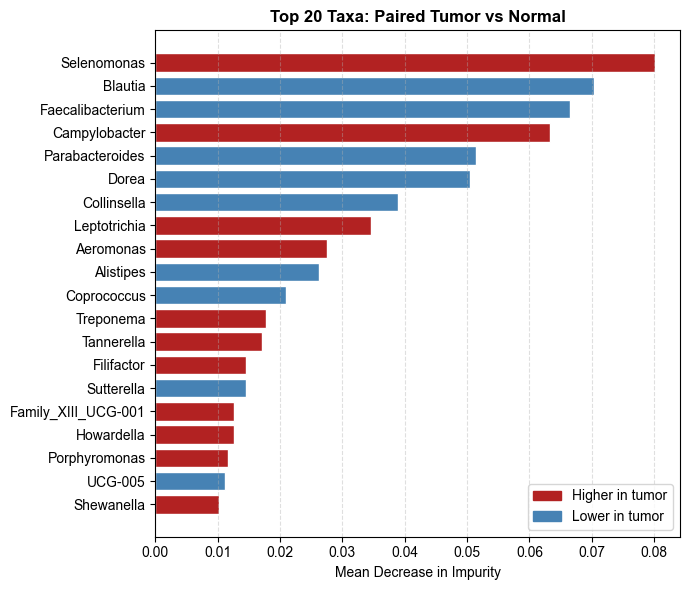

In [32]:
plot_df = summary_pair.sort_values("importance")
colors = ["firebrick" if d > 0 else "steelblue" for d in plot_df["median_delta"]]

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(plot_df.index, plot_df["importance"], color=colors, edgecolor="white")
ax.set_xlabel("Mean Decrease in Impurity")
ax.set_title(f"Top {TOP_N} Taxa: Paired Tumor vs Normal", fontweight="bold")
ax.legend(handles=[mpatches.Patch(color="firebrick", label="Higher in tumor"),
                   mpatches.Patch(color="steelblue", label="Lower in tumor")])
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
save_fig("importance_paired")
plt.show()

### Fusobacterium check!


In [33]:
fuso = [g for g in delta_df.columns if "Fusobacterium" in g]

if not fuso:
    print("Fusobacterium did not survive the prevalence/abundance filter.")
    if "Fusobacterium" in genusTable.index:
        raw = genusTable.loc["Fusobacterium"]
        print(f"  Before filtering: present in {int((raw > 0).sum())} samples, "
              f"{int(raw.sum())} reads total.")

for genus in fuso:
    r = wilcoxon_all.loc[genus]
    rank = int(imp_pair.rank(ascending=False)[genus])
    prev = int((genusTableFiltered.loc[genus] > 0).sum())
    print(f"{genus}: importance rank {rank}/{len(imp_pair)} | "
          f"median delta {r['median_delta']:+.3f} | p {r['wilcoxon_p']:.4f} | "
          f"q_all {r['q_all']:.4f} | present in {prev}/{len(clrTable)} samples")

Fusobacterium: importance rank 37/134 | median delta +0.264 | p 0.4843 | q_all 0.6122 | present in 66/101 samples


## 12. Recurrence classifiers

The same two designs applied to recurrence status. Both are evaluated with repeated
cross-validation rather than a single hold-out split, because with ~50 patients a
single 20% test set is roughly 10 patients and the resulting estimate swings wildly
(see Appendix B).

In [34]:
rf_rec = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", min_samples_leaf=2,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
)

# --- unpaired: one row per biopsy, folds grouped by patient ---------------
X_rec_s = clrTable.values
y_rec_s = LabelEncoder().fit_transform(meta["recurrence"].values)
groups_rec = meta["patient"].values

aucs_s = []
for seed in range(N_REPEATS):
    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    aucs_s.extend(cross_val_score(rf_rec, X_rec_s, y_rec_s, groups=groups_rec,
                                  cv=sgkf, scoring="roc_auc", n_jobs=-1))
aucs_s = np.array(aucs_s)
print(f"Unpaired, patient-grouped AUC: {aucs_s.mean():.3f} +/- {aucs_s.std():.3f} "
      f"(over {len(aucs_s)} folds)")

Unpaired, patient-grouped AUC: 0.637 +/- 0.145 (over 100 folds)


In [35]:
# --- paired: one row per patient, no grouping needed ----------------------
X_rec_d = delta_df.values
y_rec_d = LabelEncoder().fit_transform(patient_recurrence.loc[delta_df.index].values)

scores_d = cross_validate(
    rf_rec, X_rec_d, y_rec_d,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=N_REPEATS,
                               random_state=RANDOM_STATE),
    scoring=["roc_auc", "balanced_accuracy", "average_precision"], n_jobs=-1,
)
for m in ["roc_auc", "balanced_accuracy", "average_precision"]:
    s = scores_d["test_" + m]
    print(f"{m:20s} {s.mean():.3f} +/- {s.std():.3f}   "
          f"(2.5-97.5%: {np.percentile(s, 2.5):.3f}-{np.percentile(s, 97.5):.3f})")

roc_auc              0.546 +/- 0.173   (2.5-97.5%: 0.145-0.801)
balanced_accuracy    0.511 +/- 0.117   (2.5-97.5%: 0.267-0.700)
average_precision    0.512 +/- 0.144   (2.5-97.5%: 0.258-0.784)


observed AUC : 0.663
null mean    : 0.503  (sd 0.126)
null 95th pct: 0.698
p            : 0.1039
saved -> figures\perm_recurrence.tif  (2065x1162 px, 6.88 in wide) [ok]


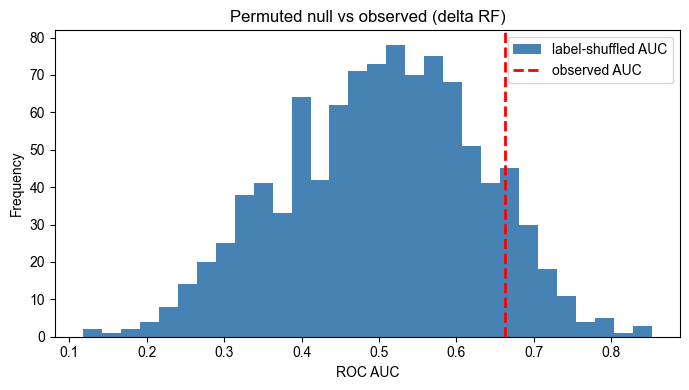

In [36]:
# --- permutation test, paired design --------------------------------------
score_rec_d, perm_rec_d, p_rec_d = permutation_test_score(
    rf_rec, X_rec_d, y_rec_d,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc", n_permutations=N_PERM_REC,
    random_state=RANDOM_STATE, n_jobs=-1,
)
print(f"observed AUC : {score_rec_d:.3f}")
print(f"null mean    : {perm_rec_d.mean():.3f}  (sd {perm_rec_d.std():.3f})")
print(f"null 95th pct: {np.percentile(perm_rec_d, 95):.3f}")
print(f"p            : {p_rec_d:.4f}")

plt.figure(figsize=(7, 4))
plt.hist(perm_rec_d, bins=30, color="steelblue", label="label-shuffled AUC")
plt.axvline(score_rec_d, color="red", ls="--", lw=2, label="observed AUC")
plt.xlabel("ROC AUC")
plt.ylabel("Frequency")
plt.legend()
plt.title("Permuted null vs observed (delta RF)")
plt.tight_layout()
save_fig("perm_recurrence")
plt.show()

In [37]:
# --- permutation test, unpaired design ------------------------------------
# Labels are shuffled at the PATIENT level, so both of a patient's biopsies keep
# the same (permuted) status. Shuffling per-sample would break the pairing and
# produce an optimistic null.
cv_rec_s = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def grouped_auc(labels):
    return cross_val_score(rf_rec, X_rec_s, labels, groups=groups_rec,
                           cv=cv_rec_s, scoring="roc_auc", n_jobs=-1).mean()


observed_rec_s = grouped_auc(y_rec_s)

patients_u = np.unique(groups_rec)
patient_label = np.array([y_rec_s[groups_rec == p][0] for p in patients_u])

rng = np.random.default_rng(RANDOM_STATE)
null_rec_s = np.empty(N_PERM_REC)
for i in range(N_PERM_REC):
    mapping = dict(zip(patients_u, rng.permutation(patient_label)))
    null_rec_s[i] = grouped_auc(np.array([mapping[g] for g in groups_rec]))

p_rec_s = (np.sum(null_rec_s >= observed_rec_s) + 1) / (N_PERM_REC + 1)
print(f"observed AUC {observed_rec_s:.3f} | null mean {null_rec_s.mean():.3f} | "
      f"p = {p_rec_s:.4f}")

observed AUC 0.604 | null mean 0.508 | p = 0.1578


In [38]:
# --- summary table for the manuscript -------------------------------------
recurrence_summary = pd.DataFrame({
    "Unpaired": [f"{len(meta)} samples",
                 f"{aucs_s.mean():.3f} +/- {aucs_s.std():.3f}",
                 "-",
                 f"{observed_rec_s:.3f}",
                 f"{null_rec_s.mean():.3f}",
                 f"{p_rec_s:.2f}"],
    "Paired":   [f"{len(delta_df)} patients",
                 f"{scores_d['test_roc_auc'].mean():.3f} +/- {scores_d['test_roc_auc'].std():.3f}",
                 f"{scores_d['test_balanced_accuracy'].mean():.3f} +/- "
                 f"{scores_d['test_balanced_accuracy'].std():.3f}",
                 f"{score_rec_d:.3f}",
                 f"{perm_rec_d.mean():.3f}",
                 f"{p_rec_d:.2f}"],
}, index=["Rows", "Mean ROC AUC", "Balanced accuracy",
          "Permutation AUC", "Null mean AUC", "p"])
print(recurrence_summary.to_string())

                          Unpaired           Paired
Rows                   101 samples      50 patients
Mean ROC AUC       0.637 +/- 0.145  0.546 +/- 0.173
Balanced accuracy                -  0.511 +/- 0.117
Permutation AUC              0.604            0.663
Null mean AUC                0.508            0.503
p                             0.16             0.10


---

# Appendix A - Shannon alpha diversity

Not used in the manuscript. Kept because the analysis was run and the conclusion
(no separation by recurrence) is worth having on record.

In [39]:
counts = genusTableFiltered.T.loc[clrTable.index]       # samples x genera, raw counts
shannon = counts.apply(lambda row: entropy(row[row > 0], base=np.e), axis=1)

shannon_df = pd.DataFrame({"shannon_diversity": shannon,
                           "recurrence": meta["recurrence"],
                           "tissue_type": meta["tissue_type"],
                           "patient": meta["patient"]})

print(shannon_df.groupby("recurrence")["shannon_diversity"].describe()[["count", "mean", "std"]])
print()
print(shannon_df.groupby("tissue_type")["shannon_diversity"].describe()[["count", "mean", "std"]])

               count      mean       std
recurrence                              
non-recurrent   66.0  2.069294  0.479076
recurrent       35.0  1.882284  0.706776

             count      mean       std
tissue_type                           
CRC normal    51.0  2.156184  0.490928
CRC tumor     50.0  1.849759  0.610808


saved -> figures\shannon_boxplots.tif  (2241x997 px, 7.47 in wide) [ok]


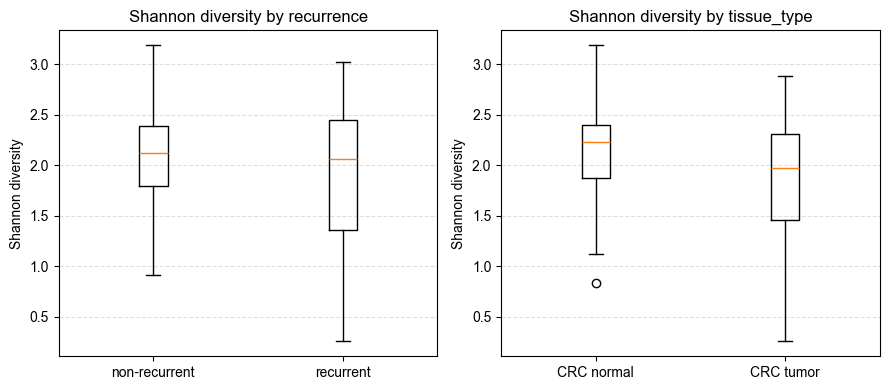

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, col in zip(axes, ["recurrence", "tissue_type"]):
    groups = sorted(shannon_df[col].unique())
    ax.boxplot([shannon_df.loc[shannon_df[col] == g, "shannon_diversity"] for g in groups])
    # set_xticklabels rather than boxplot(labels=...), which matplotlib 3.9 removed
    ax.set_xticks(range(1, len(groups) + 1))
    ax.set_xticklabels(groups)
    ax.set_ylabel("Shannon diversity")
    ax.set_title(f"Shannon diversity by {col}")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
save_fig("shannon_boxplots")
plt.show()

In [41]:
# Within-patient change in Shannon diversity (tumor minus normal).
sh_t = shannon_df[meta["tissue_code"] == "TT"].set_index(meta.loc[meta["tissue_code"] == "TT", "patient"])
sh_n = shannon_df[meta["tissue_code"] == "TN"].set_index(meta.loc[meta["tissue_code"] == "TN", "patient"])

delta_shannon = (sh_t.loc[paired_patients, "shannon_diversity"]
                 - sh_n.loc[paired_patients, "shannon_diversity"])

print(f"Median within-patient change: {delta_shannon.median():+.4f}")
print(f"Wilcoxon signed-rank p:       {wilcoxon_p(delta_shannon):.4f}")

Median within-patient change: -0.2014
Wilcoxon signed-rank p:       0.0048


---

# Appendix B - Superseded single-split models

These single 80/20 hold-out models were the earlier approach. With ~50 patients a
20% test set is about 10 patients, and the estimates proved unstable: the paired
recurrence model scored 80% accuracy here but sits at chance under the repeated
cross-validation in section 12.

In [42]:
# --- single split, unpaired recurrence ------------------------------------
le = LabelEncoder()
y_enc = le.fit_transform(meta["recurrence"].values)

Xtr, Xte, ytr, yte = train_test_split(
    clrTable.values, y_enc, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_enc,
)
rf_single = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", min_samples_leaf=2,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
).fit(Xtr, ytr)

print(f"Train {len(Xtr)} / Test {len(Xte)} samples")
print(classification_report(yte, rf_single.predict(Xte), target_names=le.classes_))
print("NOTE: this split puts a patient's two biopsies on opposite sides of the "
      "train/test boundary, which inflates the score.")

Train 80 / Test 21 samples
               precision    recall  f1-score   support

non-recurrent       0.69      0.64      0.67        14
    recurrent       0.38      0.43      0.40         7

     accuracy                           0.57        21
    macro avg       0.53      0.54      0.53        21
 weighted avg       0.59      0.57      0.58        21

NOTE: this split puts a patient's two biopsies on opposite sides of the train/test boundary, which inflates the score.


In [43]:
# --- single split, paired recurrence --------------------------------------
y_enc_d = LabelEncoder().fit_transform(patient_recurrence.loc[delta_df.index].values)

Xtr, Xte, ytr, yte = train_test_split(
    delta_df.values, y_enc_d, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_enc_d,
)
rf_single_d = RandomForestClassifier(
    n_estimators=500, max_features="sqrt", min_samples_leaf=2,
    class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1,
).fit(Xtr, ytr)

print(f"Train {len(Xtr)} / Test {len(Xte)} patients")
print(classification_report(yte, rf_single_d.predict(Xte),
                            target_names=le.classes_, zero_division=0))

Train 40 / Test 10 patients
               precision    recall  f1-score   support

non-recurrent       0.67      0.57      0.62         7
    recurrent       0.25      0.33      0.29         3

     accuracy                           0.50        10
    macro avg       0.46      0.45      0.45        10
 weighted avg       0.54      0.50      0.52        10

